In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import sys

sys.path.append(os.path.abspath('..'))

from utils.global_settings import ProjectPaths

# Set the theme
sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
START_ROUND = 17

In [18]:
# Set the paths
csv_1_epoch = os.path.join(ProjectPaths.OUTPUT_DIR, "2026-03-30-13-19-16", "round_evaluations.csv")
csv_3_epoch = os.path.join(ProjectPaths.OUTPUT_DIR, "cluster", "2026-03-28-20-32-52", "round_evaluations.csv")

# Load dataframes
df1 = pd.read_csv(csv_1_epoch)
df3 = pd.read_csv(csv_3_epoch)
df1 = df1[df1["round"] >= START_ROUND]
df3 = df3[df3["round"] >= START_ROUND]

MAX_ROUND = max(df1["round"].max(), df3["round"].max())

In [19]:
def plot_fl_backdoor_convergence(df, ax, title):
    # 1. Bar chart voor het aantal attackers (op de achtergrond)
    # Gebruik ax.twinx() NIET hiervoor, we maken een aparte Y-as voor de bars
    ax_bar = ax.twinx()
    
    # Maak de bars semi-transparant grijs
    ax_bar.bar(df['round'], df['num_attackers'], color='gray', alpha=0.2, label='# Attackers', width=0.6)
    
    # Configureer de As voor attackers (max 5 in jouw setup)
    ax_bar.set_ylim(0, 5) 
    ax_bar.set_yticks(range(6))
    ax_bar.set_ylabel('Number of Malicious Clients', color='gray', fontsize=10)
    ax_bar.tick_params(axis='y', labelcolor='gray')
    ax_bar.grid(False) # Zet gridlines uit voor de bar chart om chaos te voorkomen
    
    # DE FIX VOOR DE X-AS: Zorg dat hij strak van 17 t/m 30 loopt
    ax.set_xlim(START_ROUND - 0.5, MAX_ROUND + 0.5) 
    # Optioneel: Forceer de as om alleen hele getallen te laten zien
    ax.set_xticks(range(START_ROUND, int(MAX_ROUND) + 1, 2))
    
    # 2. Lijn voor mAP (Links)
    line1, = ax.plot(df['round'], df['mAP_50'], color='tab:blue', marker='o', markersize=4, linewidth=2, label='mAP@50 (Clean)')
    ax.set_ylim(0, 1.0)
    ax.set_ylabel('mAP@50', color='tab:blue', fontweight='bold')
    ax.tick_params(axis='y', labelcolor='tab:blue')
    ax.set_xlabel('Communication Round', fontweight='bold')

    # 3. Lijn voor ASR (Rechts)
    ax_asr = ax.twinx()
    line2, = ax_asr.plot(df['round'], df['ASR'], color='tab:red', marker='x', markersize=4, linewidth=2, linestyle='--', label='ASR (Poison)')
    ax_asr.set_ylim(0, 1.0)
    ax_asr.set_ylabel('Attack Success Rate', color='tab:red', fontweight='bold')
    ax_asr.tick_params(axis='y', labelcolor='tab:red')
    ax_asr.grid(False)

    # 4. Voeg een legend samen
    # We bundelen de lijnen en bars in 1 legend in de hoek
    bars, labels_bars = ax_bar.get_legend_handles_labels()
    lines = [line1, line2]
    labels_lines = [l.get_label() for l in lines]
    
    ax.legend(bars + lines, labels_bars + labels_lines, loc='lower right', framealpha=0.9)
    ax.set_title(title, fontweight='bold', pad=15)

    # Voorkom dat de twee rechter Y-assen over elkaar heen printen
    # De ASR as staat op de normale plek, we schuiven de Bar-as een stukje op
    ax_bar.spines["right"].set_position(("axes", 1.15))

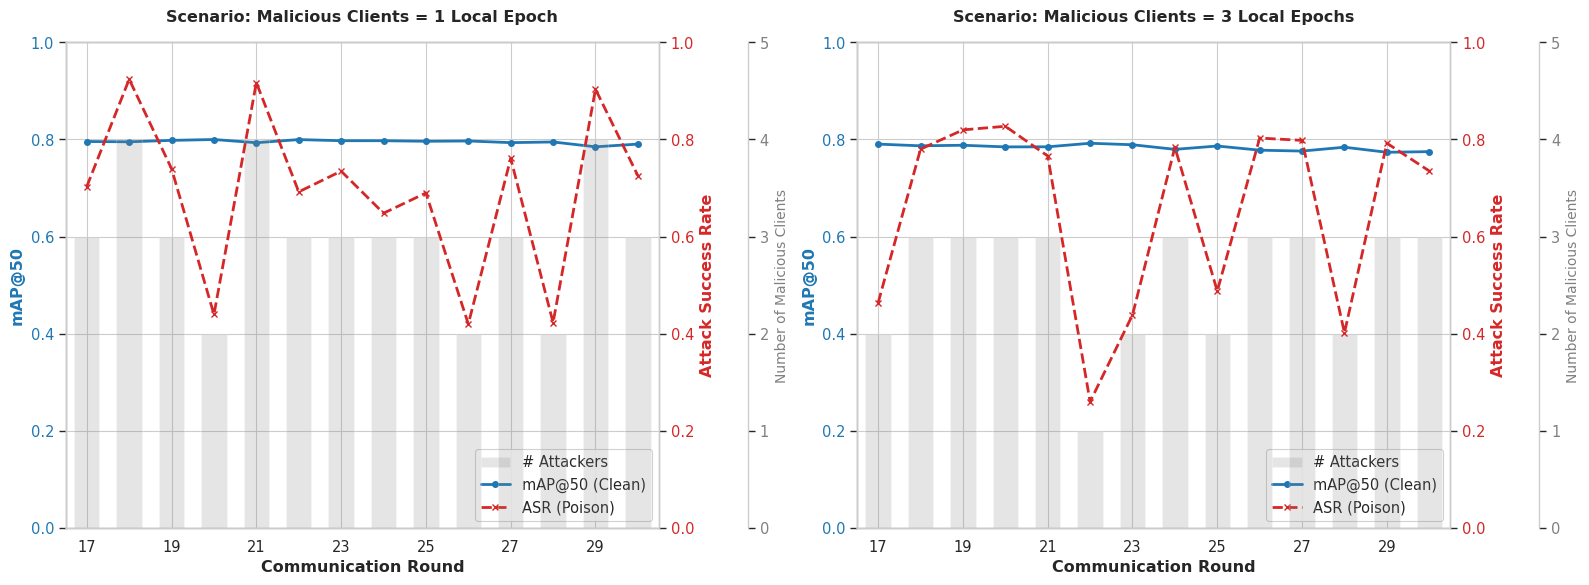

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

plot_fl_backdoor_convergence(df1, ax1, "Scenario: Malicious Clients = 1 Local Epoch")
plot_fl_backdoor_convergence(df3, ax2, "Scenario: Malicious Clients = 3 Local Epochs")

# Optimaliseer de layout zodat assen niet overlappen
fig.tight_layout()

# Sla op in hoge resolutie (perfect voor een slide of document!)
plt.savefig("epoch_amplification_comparison.png", dpi=300, bbox_inches='tight')

plt.show()